# Spatial smoothing of household demand

How much lower is the peak of *n* houses together than the sum of their own peaks?

This notebook draws synthetic household profiles from the fitted demand model (`data/demand_gmm.npz`; the training data is not needed) and computes the coincidence factor

$$T(n) = \frac{\max_t \sum_{j=1}^{n} s_j(t)}{\sum_{j=1}^{n} \max_t s_j(t)}, \qquad T(1) = 1$$

where $s_j(t)$ is house $j$'s profile in per unit of its $P_{max}$. The scenario generator turns it into power as $P_j(t) = P_{max,j}\, s_j(t)$, with $P_{max,j}$ = demand_factor × fuse-rated power of the connection.

In [1]:
import sys
sys.path[:0] = [".", ".."]          # works from injection-scenarios/ or injection-scenarios/tools/

import matplotlib.pyplot as plt
import numpy as np
from scengen.config import load_config, resolve
from scengen.models.demand import load_demand_model, sample_demand

model = load_demand_model(resolve(load_config()["scenario_defaults"]["demand"]["model_file"]))

## 1. Draw the profiles

Change `N_HOUSES` and re-run the notebook.

sum of the 1 own peaks: 0.6 pu
peak of the sum:          0.6 pu
T(1) = 1.00


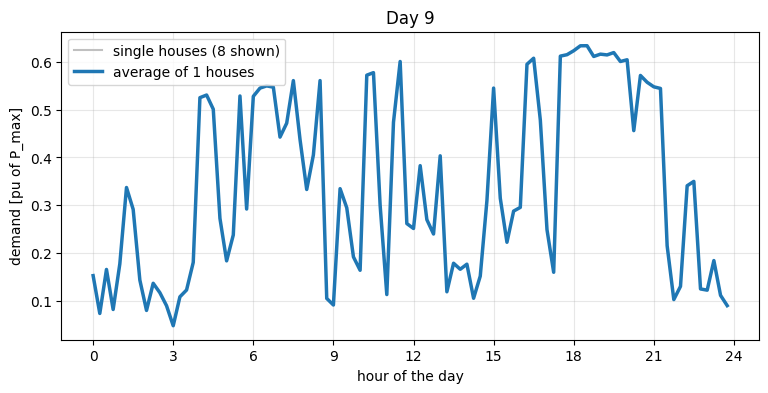

In [ ]:
import random

N_HOUSES = 1
DAYS = 365
SEED = 1

profiles, _ = sample_demand(model, N_HOUSES, range(DAYS), seed=SEED)   # [houses x days x 96 quarter-hours]
s = profiles.reshape(N_HOUSES, -1)                                    # [houses x all quarter-hours]
s.shape

own_peaks = s.max(axis=1)          # each house's own peak over the period
total = s.sum(axis=0)              # all houses together
T = total.max() / own_peaks.sum()

print(f"sum of the {N_HOUSES} own peaks: {own_peaks.sum():.1f} pu")
print(f"peak of the sum:          {total.max():.1f} pu")
print(f"T({N_HOUSES}) = {T:.2f}")

# 
day = total.argmax() // 96
hours = np.arange(96) / 4

plt.figure(figsize=(9, 4))
plt.plot(hours, profiles[:8, day].T, color="silver", linewidth=1)
plt.plot([], [], color="silver", label="single houses (8 shown)")
plt.plot(hours, profiles[:, day].mean(axis=0), color="tab:blue", linewidth=2.5, label=f"average of {N_HOUSES} houses")
plt.xlabel("hour of the day")
plt.ylabel("demand [pu of P_max]")
plt.xticks(range(0, 25, 3))
plt.title(f"Day {day}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 4. T(n) for n = 1 … N_HOUSES

Add the houses one at a time, in random order, and recompute T after each one.

In [ ]:
order = np.random.default_rng(SEED).permutation(N_HOUSES)
n = np.arange(1, N_HOUSES + 1)
T_n = np.cumsum(s[order], axis=0).max(axis=1) / np.cumsum(own_peaks[order])

plt.figure(figsize=(9, 4))
plt.plot(n, T_n, marker="o", markersize=3)
plt.xscale("log")
ticks = [t for t in (1, 2, 5, 10, 20, 50, 100, 200, 500) if t <= N_HOUSES]
plt.xticks(ticks, ticks)
plt.ylim(0, 1.05)
plt.xlabel("number of houses n")
plt.ylabel("T(n)")
plt.title("Coincidence factor: peak of the sum / sum of the peaks")
plt.grid(alpha=0.3)
plt.show()

## 5. Total energy vs number of houses

Energies simply add: the energy of n houses is the sum of their energies, so it grows linearly with n. Diversity reduces only the *peak*, which grows slower than n. Same random order of houses as above; the dashed lines are n times the average house.

In [ ]:
DT_H = 0.25                                       # one quarter-hour, in hours
energy = s.sum(axis=1) * DT_H                     # each house's energy over the period [pu·h = hours at P_max]
E_n = np.cumsum(energy[order])                    # energy of the first n houses (same order as above)
P_n = np.cumsum(s[order], axis=0).max(axis=1)     # peak of the first n houses

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
left.plot(n, E_n, marker="o", markersize=3, label="energy of n houses")
left.plot(n, n * energy.mean(), "--", color="gray", label="n × average house")
left.set(xlabel="number of houses n", ylabel="energy over the period [pu·h]", title="Energy: linear in n")
right.plot(n, P_n, marker="o", markersize=3, label="peak of n houses")
right.plot(n, n * own_peaks.mean(), "--", color="gray", label="n × average own peak")
right.set(xlabel="number of houses n", ylabel="peak [pu]", title="Peak: grows slower than n")
for ax in (left, right):
    ax.legend()
    ax.grid(alpha=0.3)
plt.show()

P_MAX_KW = 0.06 * 24.9                            # example: today's P_max of a 40 A connection (demand_factor 0.06)
print(f"energy per house: {energy.mean():.0f} pu·h over {DAYS} days = {energy.mean() * P_MAX_KW:,.0f} kWh with P_max = {P_MAX_KW:.2f} kW")

## 6. Choosing `demand_factor`: three stories

The scenario generator gives every connection $P_{max} = d \cdot \text{fuse-rated power}$, with $d$ = `demand_factor` in the scenario's `config.json`. Below are three ways to choose $d$, and what each one implies.

**Adjust the parameters in the next cell**; everything after it is computed from them, from the grid data and from the model.

In [ ]:
# =====================  PARAMETERS TO ADJUST  =====================
L_PLANNING = 0.06              # l: DSO planning value, network peak / total fuse rating      (stories 1, 2)
N_TYPICAL = None               # connections of the typical network; None = median network    (story 2)
FUSE_EXAMPLE_KW = 24.9         # example connection for the per-house numbers: 40 A = √3 · 400 V · 40 A · 0.9

CH_CONSUMPTION_TWH = 57.0      # Swiss final electricity consumption [TWh/yr]   CHECK: SFOE electricity statistics   (story 3)
SHARE_HOUSEHOLDS = 0.35        # households' share of it                         CHECK: SFOE                          (story 3)
SHARE_SERVICES = 0.27          # services' share of it                           CHECK: SFOE                          (story 3)
POP_REGION = 105_042           # population of the supply area   (config.json: 2030 projection; use the year of the consumption)
POP_CH = 9_462_900             # Swiss population, same year
# ==================================================================

### What the stories need

- From the grid (`data/lv_grids/lines.csv`, totals only): the total fuse-rated power of all connections, $\sum \text{fuse}$, and the size $N$ of the typical network.
- From the model: $y(N)$, the peak of a group of $N$ houses divided by $N$, in pu of $P_{max}$ (unlike $T(n)$ above, which divides by the houses' own peaks); and $H$, the yearly energy of one house in hours at $P_{max}$ (about 1,044 h).

In [ ]:
import pandas as pd
from scengen.config import DATA_DIR

# Grid: connections with a fuse rating (totals only)
lines = pd.read_csv(DATA_DIR / "lv_grids" / "lines.csv", usecols=["network_id", "to", "plmax_kw"])
conn = lines.drop_duplicates(["network_id", "to"]).query("plmax_kw > 0")
FUSE_TOTAL_MW = conn["plmax_kw"].sum() / 1e3
N_NETWORK = int(conn.groupby("network_id").size().median()) if N_TYPICAL is None else N_TYPICAL

# Model: a large sample of houses over one year, in pu of P_max
calib, _ = sample_demand(model, 400, range(365), seed=2)
calib = calib.reshape(400, -1)
H = calib.mean() * 8760                      # yearly energy of one house, in hours at P_max


def y(n, repeats=40):
    """Peak of a group of n houses divided by n [pu of P_max], averaged over random groups."""
    rng = np.random.default_rng(n)
    return np.mean([calib[rng.choice(len(calib), n, replace=False)].sum(axis=0).max() / n for _ in range(repeats)])


print(f"grid:  {len(conn):,} connections, total fuse-rated power {FUSE_TOTAL_MW:,.0f} MW, typical network {N_NETWORK} connections")
print(f"model: H = {H:,.0f} h at P_max per house and year;  y({N_NETWORK}) = {y(N_NETWORK):.3f}")

### The three stories

**Story 1, the 6 %.** Use the planning value as is: $d = l$. This is today's setting. But $l$ describes the *network* peak, while here it sets each house's $P_{max}$; after diversity, a typical network peaks far below $l$.

**Story 2, the 21 % (where it comes from).** A network of $N$ connections peaks at $d \cdot y(N) \cdot \sum \text{fuse}$. Asking the typical network (the median size, 27 connections) to peak at the planning value:

$$d \cdot y(N) = l \quad\Rightarrow\quad d = \frac{l}{y(N)} = \frac{0.06}{0.28} \approx 0.21$$

The same $d$ is then used for every network: smaller networks peak above $l$, larger ones below.

**Story 3, household sanity check.** Energies add up, so all connections together use $d \cdot H \cdot \sum \text{fuse}$ per year. Asking this to equal the Swiss consumption prorated to the region by population, for households only (3a) or households and services (3b):

$$d = \frac{E_{CH} \cdot \dfrac{pop_{region}}{pop_{CH}} \cdot share}{H \cdot \sum \text{fuse}}$$

This story does not use $l$ at all: it checks the energy level instead of the peak.

In [ ]:
# Story 1: the planning value as is
d_1 = L_PLANNING

# Story 2: the typical network peaks at the planning value:  d · y(N) = l
d_2 = L_PLANNING / y(N_NETWORK)

# Story 3: the yearly energy of all connections matches the national consumption prorated to the region:
#          d · H · Σ fuse = E_target
E_region = CH_CONSUMPTION_TWH * 1e3 * POP_REGION / POP_CH            # GWh/yr, all sectors
E_households = E_region * SHARE_HOUSEHOLDS
E_households_services = E_region * (SHARE_HOUSEHOLDS + SHARE_SERVICES)
d_3a = E_households / (H * FUSE_TOTAL_MW / 1e3)
d_3b = E_households_services / (H * FUSE_TOTAL_MW / 1e3)

print(f"story 1: d = l = {d_1}")
print(f"story 2: d = l / y({N_NETWORK}) = {L_PLANNING} / {y(N_NETWORK):.3f} = {d_2:.3f}")
print(f"story 3: region {E_region:,.0f} GWh/yr; households {E_households:,.0f} GWh -> d = {d_3a:.3f}; "
      f"households + services {E_households_services:,.0f} GWh -> d = {d_3b:.3f}")

### Comparison

What each choice implies: the peak of the typical network, the yearly energy of one example house, and the yearly energy of all connections. The plot shows the network peak for every network size: only story 2 is pinned to $l$, and only at the typical size.

In [ ]:
stories = {"1: planning value as is": d_1, "2: typical network at l": d_2,
           "3a: households": d_3a, "3b: households + services": d_3b}
table = pd.DataFrame([{"story": k, "demand_factor": round(d, 3),
                       "typical network peak [% of fuse]": round(100 * d * y(N_NETWORK), 1),
                       f"house on a {FUSE_EXAMPLE_KW} kW fuse [kWh/yr]": round(d * FUSE_EXAMPLE_KW * H),
                       "all connections [GWh/yr]": round(d * H * FUSE_TOTAL_MW / 1e3)} for k, d in stories.items()])
display(table)

sizes = [1, 2, 5, 10, 20, 50, 100, 200]
y_sizes = np.array([y(n) for n in sizes])
plt.figure(figsize=(9, 4))
for k, d in stories.items():
    plt.plot(sizes, 100 * d * y_sizes, marker="o", markersize=3, label=f"story {k} (d = {d:.2f})")
plt.axhline(100 * L_PLANNING, color="gray", linewidth=1)
plt.text(1, 100 * L_PLANNING, " planning value l", va="bottom", color="gray")
plt.axvline(N_NETWORK, color="gray", linewidth=1, linestyle=":")
plt.text(N_NETWORK, 0.5, f" typical network ({N_NETWORK})", color="gray")
plt.xscale("log")
plt.xticks(sizes, sizes)
plt.xlabel("connections in the network")
plt.ylabel("network peak [% of total fuse rating]")
plt.title("Network peak by network size, for each choice of demand_factor")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Caveat

The model draws every house and every day independently: no shared cold day, weekday or holiday. Real metered houses move together on such days, so for large *n* their T(n) is likely higher than here.